In [1]:
import numpy as np
import networkx as nx
import propnetscore.node_selection as ns
from coarse_graining import coarse_grain_graph, coarse_grain_prediction, coarse_grain_true_node, get_supernode_sizes


In [32]:
# Select graph

# Karate
#G = nx.karate_club_graph()

# SMB
sizes = [10, 20, 30, 40, 50]
sizes = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
#probs = [[1, 0, 0, 0, 0], [0, 1, 0, 0, 0], [0, 0, 1, 0, 0], [0, 0, 0, 1, 0], [0, 0, 0, 0, 1]]
p = 0.9  # wiring probability within blocks
q = 0.1  # wiring probability between blocks
probs = [[p,q,q,q,q], [q,p,q,q,q], [q,q,p,q,q], [q,q,q,p,q], [q,q,q,q,p]]
probs = [[p,q,q,q,q,q,q,q,q,q], [q,p,q,q,q,q,q,q,q,q], [q,q,p,q,q,q,q,q,q,q], [q,q,q,p,q,q,q,q,q,q], [q,q,q,q,p,q,q,q,q,q], [q,q,q,q,q,p,q,q,q,q], [q,q,q,q,q,q,p,q,q,q], [q,q,q,q,q,q,q,p,q,q], [q,q,q,q,q,q,q,q,p,q], [q,q,q,q,q,q,q,q,q,p]]

G = nx.stochastic_block_model(sizes, probs, seed=0)

adjacency_matrix = nx.to_numpy_array(G, weight=None)

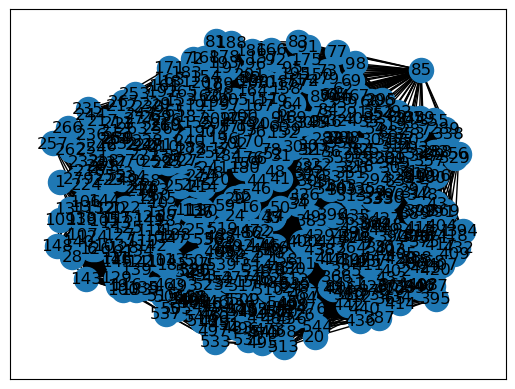

In [33]:
nx.draw_networkx(G)

In [34]:
# Set up node selection task

# 1. Ground truth
true_node = 120 #120

# 2. Generate prediction
rng = np.random.default_rng()
dimensions = len(G)  # Number of elements in each probability vector
num_samples = 1  # Number of random vectors to generate
prediction = rng.dirichlet(np.ones(dimensions), size=num_samples).flatten()
assert np.isclose(prediction.sum(), 1)
assert len(G) == len(prediction)

# 3. Set up task
task = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)


In [35]:
taus = np.logspace(np.log10(1e-2), np.log10(1e2), num=100)
ratios = []
sizes = []
diff_scores = []
brier_scores = []

# ingredients to compute the normalisation ad hoc
from scipy.linalg import expm
laplacian = nx.laplacian_matrix(G).toarray()

for tau in taus:

    print(f"tau = {tau}")

    # Diffusion score for tau=tau
    diff_score = task.diffusion_score(tau=tau, mu=0, convention='positive', normalise=True)

    # Coarse-graining
    G_cg, node_to_supernode = coarse_grain_graph(G, tau)
    cg_prediction = coarse_grain_prediction(prediction, node_to_supernode)
    cg_true_node  = coarse_grain_true_node(true_node, node_to_supernode)
    assert abs(cg_prediction.sum() - 1.0) < 1e-9  # probability still sums to 1
    assert 0 <= cg_true_node < len(G_cg)  # valid node in new graph

    # Weighted Brier score on tau-coarse-grained graph
    cg_adjacency_matrix = nx.to_numpy_array(G_cg, weight=None)
    cg_task = ns.NodeSelectionTask(cg_adjacency_matrix, cg_prediction, cg_true_node)
    weights = 1 / get_supernode_sizes(node_to_supernode)
    diffusion_kernel = expm(-0.5 * tau * laplacian)
    normalisation = np.trace(diffusion_kernel)  # Note: this is tau-dependent, but takes the FULL (not coarse-grained) Laplacian!
    cg_brier_score = cg_task.weighted_brier_score(weights=weights) / normalisation

    diff_scores.append(diff_score)
    brier_scores.append(cg_brier_score)

    ratio = 4 * diff_score / cg_brier_score
    ratios.append(ratio)

    sizes.append(len(G_cg))

ratios = np.array(ratios)
sizes = np.array(sizes)
diff_scores = np.array(diff_scores)
brier_scores = np.array(brier_scores)


tau = 0.01
tau = 0.010974987654930561
tau = 0.012045035402587823
tau = 0.013219411484660288
tau = 0.014508287784959394
tau = 0.015922827933410922
tau = 0.01747528400007684
tau = 0.019179102616724886
tau = 0.02104904144512021
tau = 0.023101297000831605
tau = 0.025353644939701114
tau = 0.027825594022071243
tau = 0.030538555088334154
tau = 0.033516026509388425
tau = 0.03678379771828634
tau = 0.040370172585965536
tau = 0.044306214575838825
tau = 0.04862601580065353
tau = 0.0533669923120631
tau = 0.05857020818056667
tau = 0.06428073117284322
tau = 0.07054802310718646
tau = 0.0774263682681127
tau = 0.08497534359086446
tau = 0.093260334688322
tau = 0.10235310218990264
tau = 0.11233240329780277
tau = 0.12328467394420665
tau = 0.13530477745798075
tau = 0.1484968262254465
tau = 0.16297508346206444
tau = 0.1788649529057435
tau = 0.19630406500402714
tau = 0.21544346900318845
tau = 0.23644894126454083
tau = 0.25950242113997374


C:\Users\ma1201204\AppData\Local\Temp\ipykernel_14124\3420785864.py:36: RuntimeWarning: divide by zero encountered in scalar divide
  ratio = 4 * diff_score / cg_brier_score


tau = 0.2848035868435802
tau = 0.3125715849688237
tau = 0.34304692863149194
tau = 0.37649358067924693
tau = 0.41320124001153385
tau = 0.4534878508128584
tau = 0.49770235643321115
tau = 0.5462277217684343
tau = 0.5994842503189411
tau = 0.6579332246575682
tau = 0.7220809018385468
tau = 0.7924828983539177
tau = 0.8697490026177834
tau = 0.9545484566618342
tau = 1.0476157527896652
tau = 1.149756995397737
tau = 1.261856883066021
tau = 1.384886371393873
tau = 1.5199110829529348
tau = 1.6681005372000592
tau = 1.8307382802953698
tau = 2.0092330025650478
tau = 2.2051307399030455
tau = 2.4201282647943834
tau = 2.656087782946687
tau = 2.9150530628251787
tau = 3.1992671377973845
tau = 3.5111917342151346
tau = 3.8535285937105312
tau = 4.229242874389499
tau = 4.641588833612782
tau = 5.09413801481638
tau = 5.590810182512229
tau = 6.135907273413176
tau = 6.7341506577508286
tau = 7.390722033525782
tau = 8.111308307896872
tau = 8.902150854450392
tau = 9.770099572992256
tau = 10.722672220103243
tau = 11.7

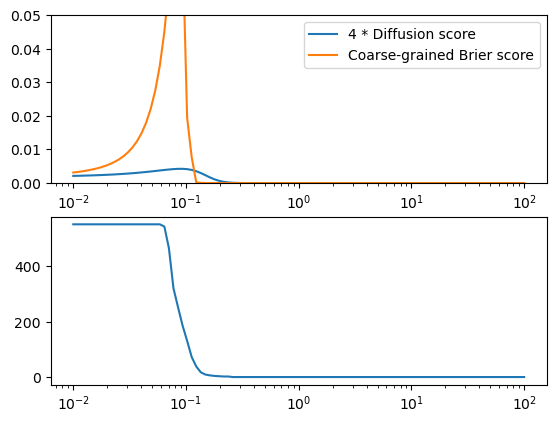

In [36]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(2, 1)

ax[0].plot(taus, 4*diff_scores, label='4 * Diffusion score')
ax[0].plot(taus, brier_scores, label='Coarse-grained Brier score')
ax[0].set_ylim(0,0.05)
ax[0].set_xscale('log')
ax[0].legend()

ax[1].plot(taus, sizes)
ax[1].set_xscale('log')


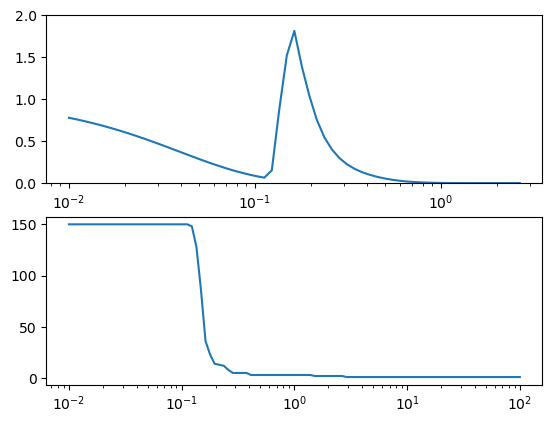

In [28]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(2, 1)

ax[0].plot(taus, ratios)
ax[0].set_ylim(0,2)
ax[0].set_xscale('log')

ax[1].plot(taus, sizes)
ax[1].set_xscale('log')


In [8]:
sample_nodes = np.arange(len(G))

# Generate prediction
rng = np.random.default_rng()
dimensions = len(G)  # Number of elements in each probability vector
num_samples = 1  # Number of random vectors to generate
prediction = rng.dirichlet(np.ones(dimensions), size=num_samples).flatten()
assert np.isclose(prediction.sum(), 1)
assert len(G) == len(prediction)
ratios = {}  # diff/brier ratios for different true nodes (keys) and taus (elements)
for true_node in sample_nodes:
    print(f"Processing true node:", true_node)
    # set up task
    task = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

    taus = np.logspace(np.log10(1e-2), np.log10(10), num=1000)
    sizes = []
    ratios[true_node] = []
    for tau in taus:
        # Diffusion score for tau=tau
        diff_score = task.diffusion_score(tau=tau, mu=0, convention='positive', normalise=True)

        # Coarse-graining
        G_cg, node_to_supernode = coarse_grain_graph(G, tau)
        cg_prediction = coarse_grain_prediction(prediction, node_to_supernode)
        cg_true_node  = coarse_grain_true_node(true_node, node_to_supernode)
        assert abs(cg_prediction.sum() - 1.0) < 1e-9  # probability still sums to 1
        assert 0 <= cg_true_node < len(G_cg)  # valid node in new graph

        # Weighted Brier score on tau-coarse-grained graph
        cg_adjacency_matrix = nx.to_numpy_array(G_cg, weight=None)
        cg_task = ns.NodeSelectionTask(cg_adjacency_matrix, cg_prediction, cg_true_node)
        weights = 1 / get_supernode_sizes(node_to_supernode)
        cg_brier_score = cg_task.weighted_brier_score(weights=weights)

        ratio = 4 * diff_score / cg_brier_score
        ratios[true_node].append(ratio)

        sizes.append(len(G_cg))


Processing true node: 0
Processing true node: 1


KeyboardInterrupt: 



In [146]:
fig, ax = plt.subplots(2, 1)

for i, true_node1 in enumerate(sample_nodes):
    for j, true_node2 in enumerate(sample_nodes):
        if j < i:
            full_ratios = np.array(ratios[true_node1])/np.array(ratios[true_node2])
            ax[0].plot(taus, full_ratios, label=f"({true_node1},{true_node2})")

ax[0].set_ylim(0,6)
ax[0].set_xscale('log')
ax[0].legend()

ax[1].plot(taus, sizes)
ax[1].set_xscale('log')



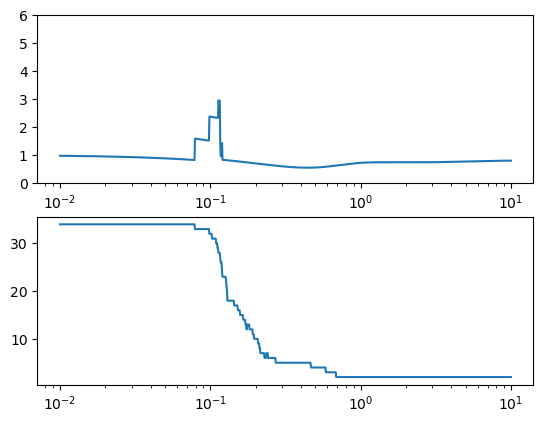

In [152]:
fig, ax = plt.subplots(2, 1)


full_ratios_sum = np.zeros(len(taus))
for i, true_node1 in enumerate(sample_nodes):
    for j, true_node2 in enumerate(sample_nodes):
        if j < i:
            full_ratios = np.array(ratios[true_node1])/np.array(ratios[true_node2])
            full_ratios_sum += full_ratios
full_ratios_mean = full_ratios_sum/(len(sample_nodes)*(len(sample_nodes)-1)/2)

ax[0].plot(taus, full_ratios)
ax[0].set_ylim(0,6)
ax[0].set_xscale('log')

ax[1].plot(taus, sizes)
ax[1].set_xscale('log')

In [153]:
# Perhaps E_i[E_j[S_tau(i,p)/S_Br(j,p)]] = 1, but what do we take the expectation over?
# What does that even tell us? Probably not much, because if we just exchange i and j of course we get 1 on average...